# Decision tree / random forest regression: predicting SBP/DBP from PPG + ECG features

Uses 6 features now: amplitude, heart rate, pulse width, augmentation index, pulse transit
time (PTT, ECG R-peak to PPG foot), and PPG intensity ratio (PIR, AC/DC per beat). PTT and PIR
are new -- added after research into other RF-based PPG BP estimation work turned up PTT+PIR+HR
as a validated combination on this exact dataset. Reads from `data/features_dataset_v2.npz`
(the original 4-feature version is still in `data/features_dataset.npz` for comparison).

Same patient-level, BP-stratified split and hyperparameter search as before.

In [1]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import matplotlib.pyplot as plt

data = np.load("data/features_dataset_v2.npz", allow_pickle=True)
feature_names = list(data["feature_names"])
X_all = data["X"]
y = data["y"]  # (N, 2): [SBP, DBP]
record_ids = data["record_ids"]

selected_features = ["amplitude", "heart_rate", "pulse_width", "augmentation_index", "ptt", "pir"]
feature_idx = [feature_names.index(name) for name in selected_features]
X = X_all[:, feature_idx]

print(f"{len(X)} windows from {len(np.unique(record_ids))} patients")


493114 windows from 11577 patients


## Patient-level, BP-stratified split

Each patient gets a median SBP, binned into 5 quantile buckets. Patients (not windows) are then
split train/test stratified on that bucket, so the distribution of blood pressures looks similar
on both sides.

In [2]:
df = pd.DataFrame({"record_id": record_ids, "sbp": y[:, 0]})
patient_median_sbp = df.groupby("record_id")["sbp"].median()
unique_records = patient_median_sbp.index.values
sbp_bins = pd.qcut(patient_median_sbp.values, q=5, labels=False, duplicates="drop")

train_records, test_records = train_test_split(
    unique_records, test_size=0.2, stratify=sbp_bins, random_state=42
)

train_mask = np.isin(record_ids, train_records)
test_mask = np.isin(record_ids, test_records)

X_train, X_test = X[train_mask], X[test_mask]
y_train, y_test = y[train_mask], y[test_mask]

print(f"train: {len(X_train)} windows from {len(train_records)} patients")
print(f"test:  {len(X_test)} windows from {len(test_records)} patients")


train: 395505 windows from 9261 patients
test:  97609 windows from 2316 patients


SBP range -- train: [80, 180] mean=127.7  |  test: [80, 180] mean=127.6
DBP range -- train: [50, 110] mean=67.3  |  test: [50, 110] mean=67.2


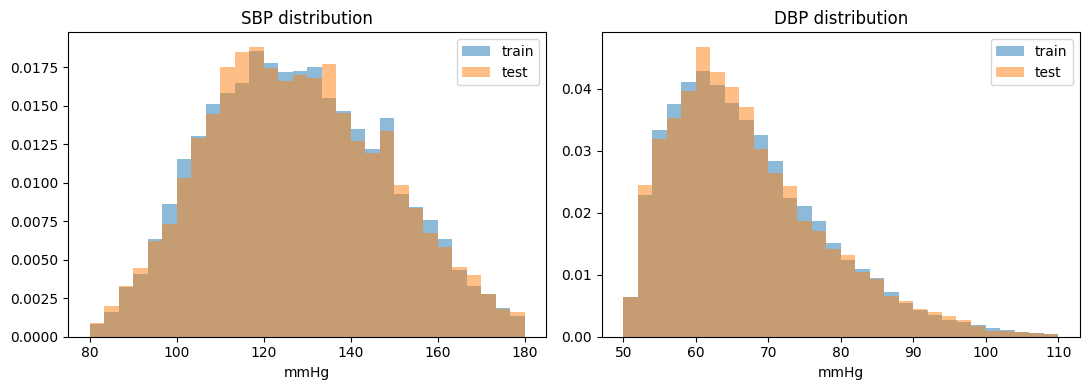

In [3]:
for i, name in enumerate(["SBP", "DBP"]):
    print(f"{name} range -- train: [{y_train[:,i].min():.0f}, {y_train[:,i].max():.0f}] "
          f"mean={y_train[:,i].mean():.1f}  |  "
          f"test: [{y_test[:,i].min():.0f}, {y_test[:,i].max():.0f}] mean={y_test[:,i].mean():.1f}")

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for i, name in enumerate(["SBP", "DBP"]):
    ax[i].hist(y_train[:, i], bins=30, alpha=0.5, density=True, label="train")
    ax[i].hist(y_test[:, i], bins=30, alpha=0.5, density=True, label="test")
    ax[i].set_title(f"{name} distribution")
    ax[i].set_xlabel("mmHg")
    ax[i].legend()
plt.tight_layout()
plt.show()


## Hyperparameter search

Grid search over `max_depth` and `min_samples_leaf`, using 3-fold group cross-validation
*within the training patients only* (grouped by `record_id`, so no patient crosses between
a fold's train/validation split either) -- the held-out test set stays untouched until the
final evaluation below. Score is the average R2 across SBP and DBP, averaged across folds.

In [4]:
from sklearn.model_selection import GroupKFold

X_tr, y_tr, groups_tr = X_train, y_train, record_ids[train_mask]

max_depth_options = [6, 8, 12, 16, None]
min_samples_leaf_options = [1, 5, 20, 50]
gkf = GroupKFold(n_splits=3)

results = []
for max_depth in max_depth_options:
    for min_samples_leaf in min_samples_leaf_options:
        fold_scores = []
        for fold_train_idx, fold_val_idx in gkf.split(X_tr, y_tr, groups=groups_tr):
            rf = RandomForestRegressor(
                n_estimators=100, max_depth=max_depth, min_samples_leaf=min_samples_leaf,
                random_state=42, n_jobs=-1
            )
            rf.fit(X_tr[fold_train_idx], y_tr[fold_train_idx])
            pred = rf.predict(X_tr[fold_val_idx])
            r2_sbp = r2_score(y_tr[fold_val_idx, 0], pred[:, 0])
            r2_dbp = r2_score(y_tr[fold_val_idx, 1], pred[:, 1])
            fold_scores.append((r2_sbp + r2_dbp) / 2)
        results.append((max_depth, min_samples_leaf, np.mean(fold_scores)))
        print(f"max_depth={max_depth} min_samples_leaf={min_samples_leaf}: "
              f"mean R2={np.mean(fold_scores):.4f}")

best_max_depth, best_min_samples_leaf, best_score = max(results, key=lambda r: r[2])
print(f"\nBest: max_depth={best_max_depth} min_samples_leaf={best_min_samples_leaf} (mean R2={best_score:.4f})")


max_depth=6 min_samples_leaf=1: mean R2=0.1116
max_depth=6 min_samples_leaf=5: mean R2=0.1116
max_depth=6 min_samples_leaf=20: mean R2=0.1115
max_depth=6 min_samples_leaf=50: mean R2=0.1114
max_depth=8 min_samples_leaf=1: mean R2=0.1452
max_depth=8 min_samples_leaf=5: mean R2=0.1451
max_depth=8 min_samples_leaf=20: mean R2=0.1447
max_depth=8 min_samples_leaf=50: mean R2=0.1437
max_depth=12 min_samples_leaf=1: mean R2=0.1966
max_depth=12 min_samples_leaf=5: mean R2=0.1964
max_depth=12 min_samples_leaf=20: mean R2=0.1933
max_depth=12 min_samples_leaf=50: mean R2=0.1881
max_depth=16 min_samples_leaf=1: mean R2=0.2238
max_depth=16 min_samples_leaf=5: mean R2=0.2233
max_depth=16 min_samples_leaf=20: mean R2=0.2170
max_depth=16 min_samples_leaf=50: mean R2=0.2070
max_depth=None min_samples_leaf=1: mean R2=0.2221
max_depth=None min_samples_leaf=5: mean R2=0.2282
max_depth=None min_samples_leaf=20: mean R2=0.2226
max_depth=None min_samples_leaf=50: mean R2=0.2107

Best: max_depth=None min_samp

In [5]:
forest = RandomForestRegressor(
    n_estimators=100, max_depth=best_max_depth, min_samples_leaf=best_min_samples_leaf,
    random_state=42, n_jobs=-1
)
forest.fit(X_train, y_train)

train_pred = forest.predict(X_train)
test_pred = forest.predict(X_test)


In [6]:
target_names = ["SBP", "DBP"]

for i, name in enumerate(target_names):
    train_mae = mean_absolute_error(y_train[:, i], train_pred[:, i])
    test_mae = mean_absolute_error(y_test[:, i], test_pred[:, i])
    train_rmse = np.sqrt(mean_squared_error(y_train[:, i], train_pred[:, i]))
    test_rmse = np.sqrt(mean_squared_error(y_test[:, i], test_pred[:, i]))
    train_r2 = r2_score(y_train[:, i], train_pred[:, i])
    test_r2 = r2_score(y_test[:, i], test_pred[:, i])
    print(f"{name}: train MAE={train_mae:.2f} RMSE={train_rmse:.2f} R2={train_r2:.3f} | "
          f"test MAE={test_mae:.2f} RMSE={test_rmse:.2f} R2={test_r2:.3f}")

print()
print("Feature importances:")
for name, imp in zip(selected_features, forest.feature_importances_):
    print(f"  {name}: {imp:.3f}")


SBP: train MAE=7.95 RMSE=10.82 R2=0.716 | test MAE=13.36 RMSE=17.37 R2=0.269
DBP: train MAE=4.82 RMSE=6.65 R2=0.612 | test MAE=7.22 RMSE=9.61 R2=0.182

Feature importances:
  amplitude: 0.168
  heart_rate: 0.194
  pulse_width: 0.151
  augmentation_index: 0.149
  ptt: 0.188
  pir: 0.150


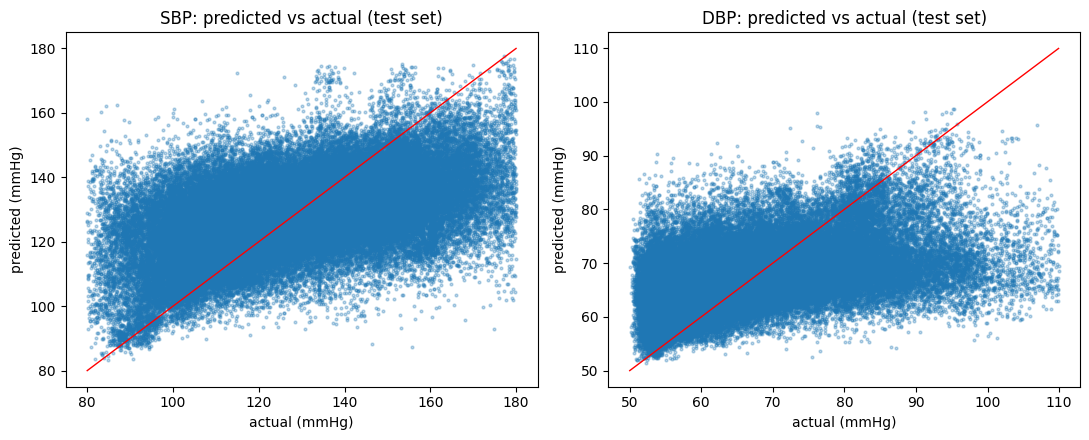

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
for i, name in enumerate(target_names):
    ax[i].scatter(y_test[:, i], test_pred[:, i], s=4, alpha=0.3)
    lims = [y_test[:, i].min(), y_test[:, i].max()]
    ax[i].plot(lims, lims, color="red", linewidth=1)
    ax[i].set_title(f"{name}: predicted vs actual (test set)")
    ax[i].set_xlabel("actual (mmHg)")
    ax[i].set_ylabel("predicted (mmHg)")
plt.tight_layout()
plt.show()
